## 1. Import

In [1]:
# Dependensi tambahan
%pip install --quiet Sastrawi==1.0.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
from __future__ import annotations

import json
import os
import random
import re
import sys
import time
import logging
import warnings
from dataclasses import dataclass, field, replace
from datetime import datetime
from typing import Any, Callable, Dict, List, Optional, Sequence, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# --- Logging ----
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-7s | %(message)s",
    datefmt="%H:%M:%S",
    stream=sys.stdout,
    force=True,
)
LOGGER = logging.getLogger("pelatihan_sentimen")
for _noisy in ("matplotlib", "PIL", "tensorflow", "absl"):
    logging.getLogger(_noisy).setLevel(logging.WARNING)

warnings.filterwarnings("ignore", category=UserWarning)
tf.get_logger().setLevel("ERROR")

# --- Reproduktibilitas -----------------------------------------------------
SEED = 42


def set_global_seed(seed: int = SEED) -> None:
    """Mengunci seluruh sumber keacakan agar hasil dapat direproduksi."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed)


set_global_seed(SEED)

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 180)
plt.rcParams["figure.dpi"] = 110

print("Informasi lingkungan eksekusi")
print("-" * 52)
print(f"Python      : {sys.version.split()[0]}")
print(f"TensorFlow  : {tf.__version__}")
print(f"Keras       : {tf.keras.__version__}")
print(f"NumPy       : {np.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"Akselerator : {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}")
print(f"Waktu mulai : {datetime.now():%Y-%m-%d %H:%M:%S}")

Informasi lingkungan eksekusi
----------------------------------------------------
Python      : 3.13.13
TensorFlow  : 2.21.0
Keras       : 3.15.0
NumPy       : 2.5.0
pandas      : 3.0.4
Akselerator : CPU
Waktu mulai : 2026-07-23 22:35:10


## 2. Konfigurasi Terpusat

In [9]:
@dataclass(frozen=True)
class LabelingConfig:
    positive_threshold: float = 1.0
    negative_threshold: float = -1.0
    negation_window: int = 2
    min_class_share: float = 0.08
    target_min_share: float = 0.15


@dataclass(frozen=True)
class TrainingConfig:
    epochs: int = 30
    batch_size: int = 128
    validation_share: float = 0.10
    early_stopping_patience: int = 5
    reduce_lr_patience: int = 2
    learning_rate: float = 1e-3
    random_state: int = SEED
    target_accuracy: float = 0.92      
    minimum_accuracy: float = 0.85     
    minimum_samples: int = 10_000      
    artifact_dir: str = "artifacts"


LABELING = LabelingConfig()
TRAINING = TrainingConfig()

# Kandidat lokasi dataset.
DATASET_CANDIDATES: Tuple[str, ...] = (
    "output/dataset_ulasan_edukasi.csv",
    "dataset_ulasan_edukasi.csv",
    "/content/dataset_ulasan_edukasi.csv",
    "/content/output/dataset_ulasan_edukasi.csv",
    "../output/dataset_ulasan_edukasi.csv",
)

os.makedirs(TRAINING.artifact_dir, exist_ok=True)

print("Konfigurasi aktif")
print("-" * 18)
print(f"Ambang polaritas positif : >= {LABELING.positive_threshold}")
print(f"Ambang polaritas negatif : <= {LABELING.negative_threshold}")
print(f"Jendela negasi           : {LABELING.negation_window} token")
print(f"Epoch maksimum           : {TRAINING.epochs}")
print(f"Ukuran batch             : {TRAINING.batch_size}")
print(f"Target akurasi (Saran 2) : > {TRAINING.target_accuracy:.0%}")
print(f"Ambang minimum (KU 4)    : >= {TRAINING.minimum_accuracy:.0%}")

Konfigurasi aktif
------------------
Ambang polaritas positif : >= 1.0
Ambang polaritas negatif : <= -1.0
Jendela negasi           : 2 token
Epoch maksimum           : 30
Ukuran batch             : 128
Target akurasi (Saran 2) : > 92%
Ambang minimum (KU 4)    : >= 85%


## 3. Pemuatan dan Verifikasi Dataset

In [14]:
REQUIRED_COLUMNS: Tuple[str, ...] = ("ulasan", "rating", "nama_aplikasi")


def resolve_dataset_path(candidates: Sequence[str]) -> str:
    for path in candidates:
        if os.path.exists(path):
            LOGGER.info("Dataset ditemukan pada: %s", path)
            return path

    raise FileNotFoundError(
        "Jalankan 'scraping_code.ipynb' "
        "terlebih dahulu, lalu letakkan berkas CSV pada salah satu lokasi berikut: "
        + ", ".join(candidates)
    )


def load_dataset(path: str) -> pd.DataFrame:
    """Memuat dataset dan menjalankan pemeriksaan integritas awal."""
    frame = pd.read_csv(path)

    missing = [col for col in REQUIRED_COLUMNS if col not in frame.columns]
    if missing:
        raise ValueError(f"Kolom wajib tidak ditemukan pada dataset: {missing}")

    before = len(frame)
    frame = frame.dropna(subset=["ulasan"])
    frame["ulasan"] = frame["ulasan"].astype(str)
    frame = frame[frame["ulasan"].str.strip().str.len() > 0].reset_index(drop=True)

    if before != len(frame):
        LOGGER.warning("%d baris tanpa teks ulasan dibuang saat pemuatan.", before - len(frame))

    return frame


DATASET_PATH = resolve_dataset_path(DATASET_CANDIDATES)
df = load_dataset(DATASET_PATH)

n_samples = len(df)
print(f"Jumlah sampel        : {n_samples:,}")
print(f"Jumlah kolom         : {df.shape[1]}")
print(f"Aplikasi sumber      : {df['nama_aplikasi'].nunique()} aplikasi")
print(f"Ambang Kriteria Utama 1 (>= 3.000)  : {'TERPENUHI' if n_samples >= 3_000 else 'GAGAL'}")
print(f"Ambang Saran ke-4     (>= 10.000)   : "
      f"{'TERPENUHI' if n_samples >= TRAINING.minimum_samples else 'PERIKSA ULANG'}")
print()
df.head(5)

22:39:46 | INFO    | Dataset ditemukan pada: dataset_ulasan_edukasi.csv
Jumlah sampel        : 11,132
Jumlah kolom         : 11
Aplikasi sumber      : 8 aplikasi
Ambang Kriteria Utama 1 (>= 3.000)  : TERPENUHI
Ambang Saran ke-4     (>= 10.000)   : TERPENUHI



,review_id,ulasan,rating,jumlah_suka,tanggal_ulasan,versi_aplikasi,app_id,nama_aplikasi,sentimen,panjang_karakter,jumlah_kata
0,2205188a-eadb-4dd4-b699-32afd5289ac6,"maaf sekali anak saya iseng mendownload dan daftar akun, maaf sekali saya ju...",1,0,7/21/2026 7:27,NaN,com.ruangguru.livestudents,Ruangguru,negatif,194,33
1,49c5c38c-7aad-49a1-8797-37f3dabcd114,JANGAN DI DOWNLOAD!!,1,0,7/20/2026 17:46,NaN,com.ruangguru.livestudents,Ruangguru,negatif,20,3
2,90bdf80e-b827-4840-9565-2bdab02f2a35,banyak banyak bebenah deh,1,0,7/20/2026 15:50,7.1.4,com.ruangguru.livestudents,Ruangguru,negatif,25,4
3,a76d4a0d-89ef-4336-9ca6-59af55c4103f,mohon maaf kak ini kenapa aplikasi nya gak bisa dibuka ya kayak di terus stu...,1,0,7/18/2026 22:52,NaN,com.ruangguru.livestudents,Ruangguru,negatif,189,35
4,a7269597-4706-48d7-b836-a7fb1034f536,"GAJELAS, BIKIN MLS. TIAP LIVE TEACHING ERROR MULU, GA MUNCUL POLLING, DI REF...",1,0,7/17/2026 16:21,7.1.4,com.ruangguru.livestudents,Ruangguru,negatif,154,26


### 3.1 Analisis Deskriptif Awal

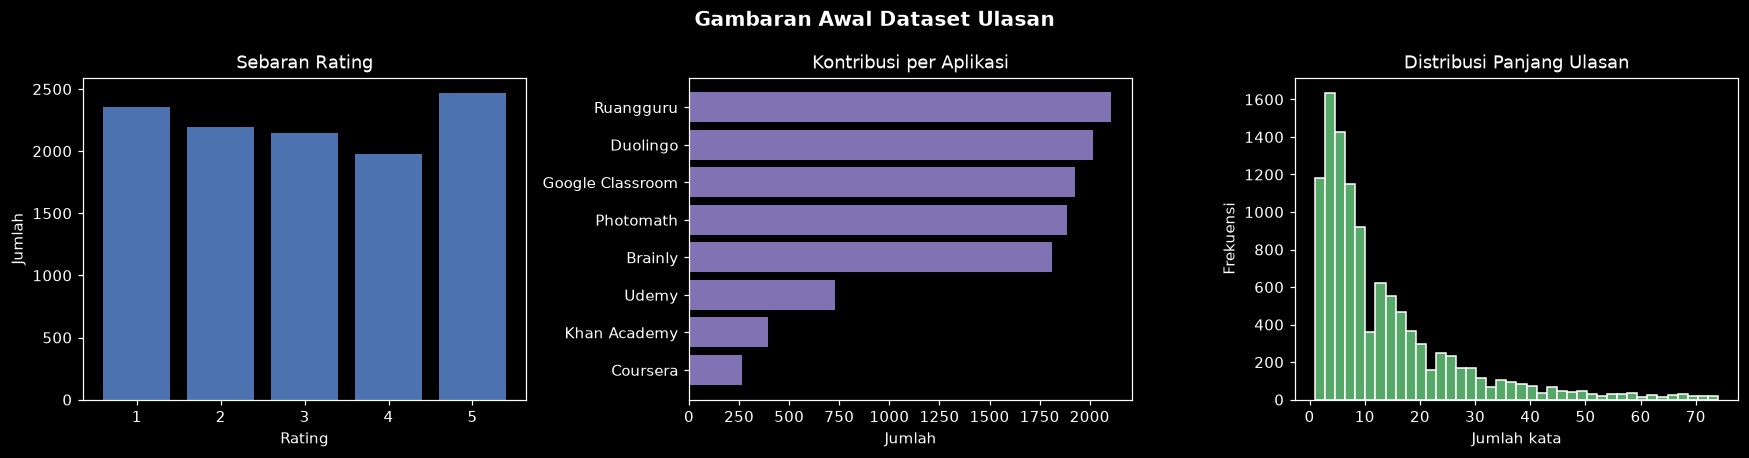

Statistik panjang ulasan (kata)
--------------------------------
Mean: 13.9
Median    : 9
Percentile 95 : 44
Maximum  : 98


In [18]:
def plot_initial_overview(frame: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    fig.suptitle("Gambaran Awal Dataset Ulasan", fontsize=13, fontweight="bold")

    rating_counts = frame["rating"].value_counts().sort_index()
    axes[0].bar(rating_counts.index.astype(str), rating_counts.values, color="#4C72B0")
    axes[0].set_title("Sebaran Rating")
    axes[0].set_xlabel("Rating")
    axes[0].set_ylabel("Jumlah")

    app_counts = frame["nama_aplikasi"].value_counts().sort_values()
    axes[1].barh(app_counts.index.astype(str), app_counts.values, color="#8172B3")
    axes[1].set_title("Kontribusi per Aplikasi")
    axes[1].set_xlabel("Jumlah")

    kata = frame["ulasan"].str.split().str.len()
    batas = kata.quantile(0.99)
    axes[2].hist(kata[kata <= batas], bins=40, color="#55A868", edgecolor="white")
    axes[2].set_title("Distribusi Panjang Ulasan")
    axes[2].set_xlabel("Jumlah kata")
    axes[2].set_ylabel("Frekuensi")

    plt.tight_layout()
    plt.show()


plot_initial_overview(df)

jumlah_kata = df["ulasan"].str.split().str.len()
print("Statistik panjang ulasan (kata)")
print("-" * 32)
print(f"Mean: {jumlah_kata.mean():.1f}")
print(f"Median    : {jumlah_kata.median():.0f}")
print(f"Percentile 95 : {jumlah_kata.quantile(0.95):.0f}")
print(f"Maximum  : {jumlah_kata.max():.0f}")

## 4. Pra-pemrosesan Teks

In [20]:
# --- Kamus normalisasi ragam informal -> bentuk baku ------------
SLANG_DICTIONARY: Dict[str, str] = {
    # Negasi dan partikel
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "nggak": "tidak", "ngga": "tidak",
    "enggak": "tidak", "tdk": "tidak", "tk": "tidak", "g": "tidak", "kagak": "tidak",
    "gabisa": "tidak bisa", "gbs": "tidak bisa", "gada": "tidak ada", "gaada": "tidak ada",
    "blm": "belum", "blum": "belum", "lom": "belum", "bkn": "bukan",
    # Kata ganti
    "sy": "saya", "gw": "saya", "gue": "saya", "ane": "saya", "aq": "saya", "gua": "saya",
    # Konjungsi dan penghubung
    "tp": "tapi", "tpi": "tapi", "krn": "karena", "krna": "karena", "utk": "untuk",
    "dgn": "dengan", "yg": "yang", "jd": "jadi", "jg": "juga", "dr": "dari",
    "kalo": "kalau", "klo": "kalau", "kl": "kalau", "trus": "terus", "trs": "terus",
    "cm": "cuma", "cuman": "cuma", "cmn": "cuma", "aja": "saja", "aj": "saja",
    "doang": "saja", "sm": "sama", "sma": "sama", "hrs": "harus", "pdhl": "padahal",
    # Adverbia dan intensifier
    "bgt": "banget", "bngt": "banget", "bgd": "banget", "bet": "banget",
    "sngt": "sangat", "sgt": "sangat", "skli": "sekali", "bnyk": "banyak", "byk": "banyak",
    "udh": "sudah", "udah": "sudah", "dah": "sudah", "sdh": "sudah",
    "skrg": "sekarang", "skg": "sekarang", "emg": "memang", "emang": "memang",
    # Evaluatif
    "bgs": "bagus", "bgus": "bagus", "mantul": "mantap", "mantep": "mantap",
    "mantab": "mantap", "manteb": "mantap", "jos": "bagus", "joss": "bagus",
    "sip": "bagus", "keceh": "keren", "kece": "keren", "ok": "oke", "okey": "oke",
    "oks": "oke", "jlk": "jelek", "bapuk": "buruk", "ampas": "buruk", "zonk": "mengecewakan",
    "recomended": "rekomendasi", "rekomended": "rekomendasi", "recommended": "rekomendasi",
    "nyesel": "menyesal", "kesel": "kesal", "males": "malas", "ribet": "rumit",
    "seneng": "senang", "bener": "benar", "bner": "benar", "bnr": "benar",
    # Kendala teknis
    "lemot": "lambat", "lelet": "lambat", "lola": "lambat", "lag": "lambat",
    "ngelag": "lambat", "eror": "error", "erorr": "error", "ngebug": "bug",
    "fc": "error", "forceclose": "error", "ngehang": "macet", "hang": "macet",
    # Istilah domain
    "apk": "aplikasi", "app": "aplikasi", "aplikasinya": "aplikasi", "apknya": "aplikasi",
    "hp": "ponsel", "henpon": "ponsel", "updet": "pembaruan", "update": "pembaruan",
    "iklannya": "iklan", "ads": "iklan", "premium": "premium", "gratisan": "gratis",
    "materinya": "materi", "gurunya": "guru", "soalnya": "soal", "fiturnya": "fitur",
    # Ekspresi lain
    "makasih": "terima kasih", "mksh": "terima kasih", "trims": "terima kasih",
    "thx": "terima kasih", "tq": "terima kasih", "plis": "tolong", "pls": "tolong",
    "gmn": "bagaimana", "gimana": "bagaimana", "gmna": "bagaimana",
    "knp": "kenapa", "knpa": "kenapa", "gitu": "begitu", "gini": "begini",
    "pake": "pakai", "pk": "pakai", "dpt": "dapat", "bikin": "membuat", "bkin": "membuat",
}

# --- Pola regex pembersihan ---
RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_MENTION = re.compile(r"[@#]\w+")
RE_NON_ALPHA = re.compile(r"[^a-z\s]")
RE_ELONGATION = re.compile(r"(.)\1{2,}")
RE_WHITESPACE = re.compile(r"\s+")

print(f"Entri kamus normalisasi slang : {len(SLANG_DICTIONARY)}")

Entri kamus normalisasi slang : 142


### 4.1 Fungsi Pra-pemrosesan

In [ ]:
_STEMMER = StemmerFactory().create_stemmer()
_BASE_STOPWORDS = set(StopWordRemoverFactory().get_stop_words())


def basic_clean(text: str) -> str:
    text = str(text).lower()
    text = RE_URL.sub(" ", text)
    text = RE_MENTION.sub(" ", text)
    text = RE_NON_ALPHA.sub(" ", text)
    text = RE_ELONGATION.sub(r"\1", text)
    return RE_WHITESPACE.sub(" ", text).strip()


def normalise_slang(tokens: Sequence[str],
                    mapping: Dict[str, str] = SLANG_DICTIONARY) -> List[str]:
    expanded: List[str] = []
    for token in tokens:
        replacement = mapping.get(token, token)
        expanded.extend(replacement.split() if " " in replacement else [replacement])
    return expanded


class StemCache:
    """Memoisasi hasil stemming pada tingkat tipe token."""

    def __init__(self, stemmer: Any) -> None:
        self._stemmer = stemmer
        self._cache: Dict[str, str] = {}

    def stem(self, token: str) -> str:
        """Mengembalikan bentuk akar sebuah token, menggunakan cache bila tersedia."""
        if token not in self._cache:
            self._cache[token] = self._stemmer.stem(token)
        return self._cache[token]

    def warm_up(self, token_types: Sequence[str]) -> None:
        """Mengisi cache untuk seluruh tipe token korpus sekaligus."""
        started = time.time()
        for token in token_types:
            self.stem(token)
        LOGGER.info("Cache stemming terisi: %d tipe token dalam %.1f detik",
                    len(self._cache), time.time() - started)

    @property
    def size(self) -> int:
        return len(self._cache)


STEM_CACHE = StemCache(_STEMMER)
print("Komponen pra-pemrosesan siap.")
print(f"Stopword bawaan Sastrawi : {len(_BASE_STOPWORDS)} kata")

Komponen pra-pemrosesan siap.
Stopword bawaan Sastrawi : 123 kata


## 5. Pelabelan Data Berbasis Lexicon

In [29]:
# --- Leksikon sentimen terbobot, diadaptasi untuk domain ulasan aplikasi ----

POSITIVE_LEXICON: Dict[str, float] = {
    # Muatan kuat
    "sempurna": 2.0, "luar biasa": 2.0, "terbaik": 2.0, "hebat": 2.0, "memuaskan": 2.0,
    "mantap": 2.0, "keren": 2.0, "rekomendasi": 2.0, "bermanfaat": 2.0, "membantu": 2.0,
    "menakjubkan": 2.0, "unggul": 2.0, "istimewa": 2.0, "brilian": 2.0, "juara": 2.0,
    # Muatan sedang
    "bagus": 1.0, "baik": 1.0, "puas": 1.0, "suka": 1.0, "senang": 1.0, "oke": 1.0,
    "mudah": 1.0, "gampang": 1.0, "cepat": 1.0, "lancar": 1.0, "jelas": 1.0,
    "lengkap": 1.0, "murah": 1.0, "terjangkau": 1.0, "ramah": 1.0, "nyaman": 1.0,
    "menarik": 1.0, "seru": 1.0, "asyik": 1.0, "cocok": 1.0, "efektif": 1.0,
    "efisien": 1.0, "informatif": 1.0, "edukatif": 1.0, "kreatif": 1.0, "inovatif": 1.0,
    "responsif": 1.0, "stabil": 1.0, "ringan": 1.0, "praktis": 1.0, "akurat": 1.0,
    "berkualitas": 1.0, "berguna": 1.0, "paham": 1.0, "mengerti": 1.0, "pintar": 1.0,
    "cerdas": 1.0, "favorit": 1.0, "andalan": 1.0, "solutif": 1.0, "gratis": 1.0,
    "hemat": 1.0, "aman": 1.0, "terpercaya": 1.0, "profesional": 1.0, "sopan": 1.0,
    "sabar": 1.0, "detail": 1.0, "rinci": 1.0, "sistematis": 1.0, "terstruktur": 1.0,
    "menyenangkan": 1.0, "inspiratif": 1.0, "motivasi": 1.0, "semangat": 1.0,
    "bermutu": 1.0, "canggih": 1.0, "modern": 1.0, "simpel": 1.0, "sukses": 1.0,
    "berhasil": 1.0, "meningkat": 1.0, "memadai": 1.0, "apik": 1.0, "top": 1.0,
    "terima kasih": 1.0, "sukses": 1.0, "bintang": 0.0,
}

NEGATIVE_LEXICON: Dict[str, float] = {
    # Muatan kuat
    "buruk": -2.0, "parah": -2.0, "payah": -2.0, "mengecewakan": -2.0, "kecewa": -2.0,
    "sampah": -2.0, "menipu": -2.0, "penipuan": -2.0, "scam": -2.0, "rugi": -2.0,
    "merugikan": -2.0, "menyebalkan": -2.0, "menjengkelkan": -2.0, "percuma": -2.0,
    "menyesal": -2.0, "kapok": -2.0, "gagal": -2.0, "rusak": -2.0, "sia sia": -2.0,
    # Muatan sedang
    "jelek": -1.0, "error": -1.0, "bug": -1.0, "lambat": -1.0, "berat": -1.0,
    "macet": -1.0, "susah": -1.0, "sulit": -1.0, "rumit": -1.0, "membingungkan": -1.0,
    "bingung": -1.0, "mahal": -1.0, "kemahalan": -1.0, "boros": -1.0, "iklan": -1.0,
    "spam": -1.0, "bohong": -1.0, "palsu": -1.0, "curang": -1.0, "hilang": -1.0,
    "kosong": -1.0, "terbatas": -1.0, "minim": -1.0, "buang": -1.0, "kesal": -1.0,
    "marah": -1.0, "benci": -1.0, "telat": -1.0, "terlambat": -1.0, "bermasalah": -1.0,
    "masalah": -1.0, "kendala": -1.0, "gangguan": -1.0, "mengganggu": -1.0,
    "terganggu": -1.0, "keluhan": -1.0, "komplain": -1.0, "memaksa": -1.0,
    "dipaksa": -1.0, "berbayar": -1.0, "malas": -1.0, "lelah": -1.0, "capek": -1.0,
    "aneh": -1.0, "kacau": -1.0, "berantakan": -1.0, "tertipu": -1.0, "menurun": -1.0,
    "menghilang": -1.0, "keluar sendiri": -1.0, "tidak stabil": -1.0, "uninstall": -1.0,
    "hapus": -1.0, "perbaiki": -1.0, "kurangi": -1.0,
}

SENTIMENT_LEXICON: Dict[str, float] = {**POSITIVE_LEXICON, **NEGATIVE_LEXICON}
SENTIMENT_LEXICON = {k: v for k, v in SENTIMENT_LEXICON.items() if v != 0.0}

# --- Negator: membalik polaritas ---
NEGATORS: frozenset = frozenset({
    "tidak", "tak", "bukan", "jangan", "belum", "kurang", "tanpa", "gagal", "hindari",
})

# --- Intensifier dan downtoner: mengubah magnitudo polaritas ---
INTENSIFIERS: Dict[str, float] = {
    "sangat": 1.6, "sekali": 1.6, "banget": 1.6, "amat": 1.6, "paling": 1.6,
    "sungguh": 1.5, "benar benar": 1.5, "terlalu": 1.3, "lebih": 1.2, "makin": 1.2,
    "semakin": 1.2, "agak": 0.6, "sedikit": 0.6, "lumayan": 0.6, "cukup": 0.7,
    "sedikit banyak": 0.6, "hampir": 0.7,
}

# Token yang tidak boleh dibuang
PROTECTED_TOKENS: frozenset = frozenset(
    set(SENTIMENT_LEXICON) | set(NEGATORS) | set(INTENSIFIERS)
)
ACTIVE_STOPWORDS: frozenset = frozenset(_BASE_STOPWORDS - PROTECTED_TOKENS)

print(f"Positive lexicon entries  : {len([v for v in SENTIMENT_LEXICON.values() if v > 0])}")
print(f"Negative lexicon entries  : {len([v for v in SENTIMENT_LEXICON.values() if v < 0])}")
print(f"Negator                   : {len(NEGATORS)}")
print(f"Intensifier/downtoner     : {len(INTENSIFIERS)}")
print(f"Active stopword           : {len(ACTIVE_STOPWORDS)} "
      f"(from {len(_BASE_STOPWORDS)}, {len(_BASE_STOPWORDS) - len(ACTIVE_STOPWORDS)} protected)")
print()
print("Contoh negator yang diselamatkan dari daftar stopword:")
print(" ", sorted(set(_BASE_STOPWORDS) & PROTECTED_TOKENS)[:12])

Positive lexicon entries  : 81
Negative lexicon entries  : 74
Negator                   : 9
Intensifier/downtoner     : 17
Active stopword           : 118 (from 123, 5 protected)

Contoh negator yang diselamatkan dari daftar stopword:
  ['agak', 'amat', 'belum', 'tanpa', 'tidak']


### 5.1 Mesin Penilaian Polaritas

In [ ]:
CLASS_ORDER: Tuple[str, ...] = ("negatif", "netral", "positif")


def score_polarity(tokens: Sequence[str],
                   lexicon: Dict[str, float] = SENTIMENT_LEXICON,
                   negators: frozenset = NEGATORS,
                   intensifiers: Dict[str, float] = INTENSIFIERS,
                   window: int = LABELING.negation_window) -> float:
    """Menghitung skor polaritas dengan penanganan negasi dan intensitas.
    """
    total = 0.0
    negation_countdown = 0
    pending_multiplier = 1.0

    for token in tokens:
        if token in negators:
            negation_countdown = window + 1
            pending_multiplier = 1.0
            continue

        if token in intensifiers:
            pending_multiplier = intensifiers[token]
            if negation_countdown > 0:
                negation_countdown += 1
            continue

        weight = lexicon.get(token)
        if weight is not None:
            sign = -1.0 if negation_countdown > 0 else 1.0
            total += sign * pending_multiplier * weight
            pending_multiplier = 1.0

        if negation_countdown > 0:
            negation_countdown -= 1

    return total


def assign_label(score: float, cfg: LabelingConfig) -> str:
    """Memetakan skor polaritas menjadi label kategorikal."""
    if score >= cfg.positive_threshold:
        return "positif"
    if score <= cfg.negative_threshold:
        return "negatif"
    return "netral"


# --- Uji cepat ---
UJI_KALIMAT = [
    "aplikasi ini sangat membantu",
    "aplikasi ini tidak membantu",
    "aplikasi ini tidak buruk",
    "materinya bagus tapi aplikasinya lemot",
    "agak bagus",
    "penjelasan guru sangat jelas dan lengkap",
    "sudah bayar tapi tetap error dan mengecewakan",
    "aplikasi dibuka setiap hari",
]

hasil_uji = pd.DataFrame([
    {
        "kalimat": kal,
        "skor": round(score_polarity(normalise_slang(basic_clean(kal).split())), 2),
        "label": assign_label(
            score_polarity(normalise_slang(basic_clean(kal).split())), LABELING),
    }
    for kal in UJI_KALIMAT
])

print("Verifikasi perilaku mesin penilaian polaritas")
print("(perhatikan baris 2 dan 3: negasi membalik polaritas dengan benar)")
print()
hasil_uji

Verifikasi perilaku mesin penilaian polaritas
(perhatikan baris 2 dan 3: negasi membalik polaritas dengan benar)



,kalimat,skor,label
0,aplikasi ini sangat membantu,3.2,positif
1,aplikasi ini tidak membantu,-2.0,negatif
2,aplikasi ini tidak buruk,2.0,positif
3,materinya bagus tapi aplikasinya lemot,0.0,netral
4,agak bagus,0.6,netral
5,penjelasan guru sangat jelas dan lengkap,2.6,positif
6,sudah bayar tapi tetap error dan mengecewakan,-3.0,negatif
7,aplikasi dibuka setiap hari,0.0,netral


### 5.2 Eksekusi Pra-pemrosesan dan Pelabelan

In [32]:
def preprocess_corpus(frame: pd.DataFrame,
                      stem_cache: StemCache,
                      cfg: LabelingConfig) -> pd.DataFrame:
    """Menjalankan pipeline pra-pemrosesan dan pelabelan.
    """
    working = frame.copy()
    started = time.time()

    # Tahap 1-3: pembersihan dasar.
    LOGGER.info("Tahap 1-3: pembersihan dasar dan reduksi elongasi ...")
    cleaned = working["ulasan"].map(basic_clean)

    # Tahap 4: normalisasi ragam informal.
    LOGGER.info("Tahap 4: normalisasi slang ...")
    token_lists = [normalise_slang(text.split()) for text in cleaned]

    # Tahap 5: pelabelan pada token.
    LOGGER.info("Tahap 5: penilaian polaritas dan pelabelan ...")
    working["skor_polaritas"] = [score_polarity(tokens) for tokens in token_lists]
    working["teks_normal"] = [" ".join(tokens) for tokens in token_lists]

    # Tahap 6: penghapusan stopword.
    LOGGER.info("Tahap 6: penghapusan stopword (token bermakna dilindungi) ...")
    filtered = [[t for t in tokens if t not in ACTIVE_STOPWORDS] for tokens in token_lists]

    # Tahap 7: stemming dengan memoisasi.
    LOGGER.info("Tahap 7: stemming dengan cache ...")
    unique_types = sorted({t for tokens in filtered for t in tokens})
    stem_cache.warm_up(unique_types)
    stemmed = [[stem_cache.stem(t) for t in tokens] for tokens in filtered]

    working["teks_bersih"] = [" ".join(tokens) for tokens in stemmed]
    working["jumlah_token"] = [len(tokens) for tokens in stemmed]

    LOGGER.info("Pra-pemrosesan selesai dalam %.1f detik.", time.time() - started)
    return working


df_prep = preprocess_corpus(df, STEM_CACHE, LABELING)

# Ulasan yang menjadi kosong setelah pra-pemrosesan.
sebelum = len(df_prep)
df_prep = df_prep[df_prep["jumlah_token"] > 0].reset_index(drop=True)
if sebelum != len(df_prep):
    LOGGER.warning("%d ulasan menjadi kosong setelah pra-pemrosesan dan dibuang.",
                   sebelum - len(df_prep))

print(f"\nSampel siap pakai : {len(df_prep):,}")
print(f"Tipe token unik   : {STEM_CACHE.size:,}")
print()
df_prep[["ulasan", "teks_bersih", "skor_polaritas"]].head(5)

22:50:41 | INFO    | Tahap 1-3: pembersihan dasar dan reduksi elongasi ...
22:50:41 | INFO    | Tahap 4: normalisasi slang ...
22:50:41 | INFO    | Tahap 5: penilaian polaritas dan pelabelan ...
22:50:41 | INFO    | Tahap 6: penghapusan stopword (token bermakna dilindungi) ...
22:50:41 | INFO    | Tahap 7: stemming dengan cache ...
23:09:44 | INFO    | Cache stemming terisi: 10390 tipe token dalam 1142.9 detik
23:09:44 | INFO    | Pra-pemrosesan selesai dalam 1143.6 detik.
23:09:45 | WARNING | 4 ulasan menjadi kosong setelah pra-pemrosesan dan dibuang.

Sampel siap pakai : 11,128
Tipe token unik   : 10,390



,ulasan,teks_bersih,skor_polaritas
0,"maaf sekali anak saya iseng mendownload dan daftar akun, maaf sekali saya ju...",maaf sekali anak iseng mendownload daftar akun maaf sekali tidak tau aplikas...,-2.0
1,JANGAN DI DOWNLOAD!!,jangan download,0.0
2,banyak banyak bebenah deh,banyak banyak bebenah deh,0.0
3,mohon maaf kak ini kenapa aplikasi nya gak bisa dibuka ya kayak di terus stu...,mohon maaf kak aplikasi nya tidak buka kayak terus stuck tampil awal plus ka...,0.0
4,"GAJELAS, BIKIN MLS. TIAP LIVE TEACHING ERROR MULU, GA MUNCUL POLLING, DI REF...",gajelas buat mls tiap live teaching error mulu tidak muncul polling refresh ...,-1.0


### 5.3 Kalibrasi Threshold dan Distribusi Kelas

In [43]:
def calibrate_thresholds(scores: pd.Series,
                         cfg: LabelingConfig) -> Tuple[float, float, bool]:
    """Menyesuaikan threshold polaritas.
    """
    labels = scores.map(lambda s: assign_label(s, cfg))
    shares = labels.value_counts(normalize=True).reindex(CLASS_ORDER).fillna(0.0)

    if shares.min() >= cfg.min_class_share:
        LOGGER.info("Adequate distribution (minimum %.1f%%).",
                    shares.min() * 100)
        return cfg.positive_threshold, cfg.negative_threshold, False

    kelas_kecil = shares.idxmin()
    LOGGER.warning("Kelas '%s' hanya %.1f%% dari data. Menjalankan kalibrasi ambang kuantil.",
                   kelas_kecil, shares.min() * 100)

    # Threshold ditarik dari kuantil simetris sehingga sisanya menjadi netral.
    neg_threshold = float(scores.quantile(cfg.target_min_share))
    pos_threshold = float(scores.quantile(1 - cfg.target_min_share))

    # Penjagaan koherensi: threshold negatif wajib berada di bawah threshold positif.
    if not neg_threshold < pos_threshold:
        LOGGER.warning(
            neg_threshold, pos_threshold,
        )
        return cfg.positive_threshold, cfg.negative_threshold, False

    LOGGER.info("Calibrated threshold -> positive >= %.2f | negative <= %.2f",
                pos_threshold, neg_threshold)
    return pos_threshold, neg_threshold, True


POS_THRESHOLD, NEG_THRESHOLD, DIKALIBRASI = calibrate_thresholds(
    df_prep["skor_polaritas"], LABELING)

CALIBRATED = replace(LABELING,
                     positive_threshold=POS_THRESHOLD,
                     negative_threshold=NEG_THRESHOLD)

df_prep["sentiment"] = df_prep["skor_polaritas"].map(lambda s: assign_label(s, CALIBRATED))

distribusi = df_prep["sentiment"].value_counts().reindex(CLASS_ORDER).rename("amount").to_frame()
distribusi["proportion_%"] = (distribusi["amount"] / len(df_prep) * 100).round(2)

print(f"Final threshold  : positive >= {POS_THRESHOLD:+.2f} | negative <= {NEG_THRESHOLD:+.2f}")
print(f"Calibrated   : {'yes' if DIKALIBRASI else 'no'}")
print(f"Number of classes  : {df_prep['sentiment'].nunique()}")
print()
distribusi

23:18:58 | INFO    | Adequate distribution (minimum 21.1%).
Final threshold  : positive >= +1.00 | negative <= -1.00
Calibrated   : no
Number of classes  : 3



,amount,proportion_%
sentiment,,
negatif,2348,21.10
netral,5006,44.99
positif,3774,33.91


### 5.4 Validasi Silang Label terhadap Sinyal Rating

In [49]:
RATING_MAP: Dict[int, str] = {1: "negatif", 2: "negatif", 3: "netral",
                              4: "positif", 5: "positif"}

df_prep["sentimen_rating"] = df_prep["rating"].map(RATING_MAP)

tabulasi = pd.crosstab(
    df_prep["sentimen_rating"].reindex(df_prep.index),
    df_prep["sentimen"],
    rownames=["Label dari rating"],
    colnames=["Label dari leksikon"],
).reindex(index=CLASS_ORDER, columns=CLASS_ORDER, fill_value=0)

kesepakatan = float((df_prep["sentimen"] == df_prep["sentimen_rating"]).mean())
kappa = cohen_kappa_score(df_prep["sentimen_rating"], df_prep["sentimen"])

# Kesepakatan pada sumbu polaritas saja
mask_polar = (df_prep["sentimen"] != "netral") & (df_prep["sentimen_rating"] != "netral")
kesepakatan_polar = float(
    (df_prep.loc[mask_polar, "sentimen"] == df_prep.loc[mask_polar, "sentimen_rating"]).mean()
)

print("Validasi antara dua sumber label")
print("-" * 32)
print(f"Validasi menyeluruh (3 class) : {kesepakatan:.1%}")
print(f"Validasi arah polaritas  : {kesepakatan_polar:.1%}")
print(f"Cohen's kappa                    : {kappa:.3f}")
print()
print("Kappa interpretation: <0,20 very weak | 0,21-0,40 weak | 0,41-0,60 moderate |")
print("                    0,61-0,80 strong     | >0,80 very strong")
print()
tabulasi

Validasi antara dua sumber label
--------------------------------
Validasi menyeluruh (3 class) : 46.7%
Validasi arah polaritas  : 82.1%
Cohen's kappa                    : 0.229

Kappa interpretation: <0,20 very weak | 0,21-0,40 weak | 0,41-0,60 moderate |
                    0,61-0,80 strong     | >0,80 very strong



Label dari leksikon,negatif,netral,positif
Label dari rating,,,
negatif,1649,2212,684
netral,484,1055,602
positif,215,1739,2488


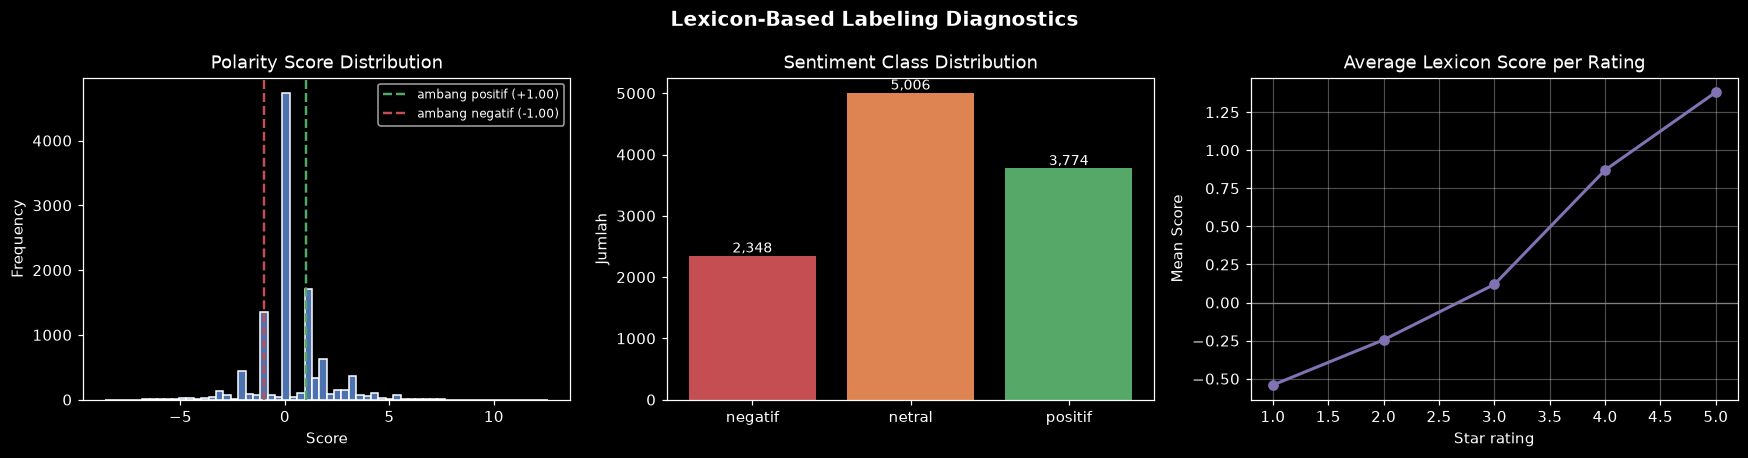

Spearman correlation lexicon score vs rating : 0.471
A positive value means both signals are moving in the same direction: validitas konvergen.


In [54]:
def plot_labeling_diagnostics(frame: pd.DataFrame) -> None:
    """Menampilkan diagnostik distribusi skor dan keseimbangan kelas."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    fig.suptitle("Lexicon-Based Labeling Diagnostics", fontsize=13, fontweight="bold")

    # Distribusi skor polaritas dengan penanda ambang.
    axes[0].hist(frame["skor_polaritas"], bins=60, color="#4C72B0", edgecolor="white")
    axes[0].axvline(POS_THRESHOLD, color="#55A868", linestyle="--", linewidth=1.6,
                    label=f"ambang positif ({POS_THRESHOLD:+.2f})")
    axes[0].axvline(NEG_THRESHOLD, color="#C44E52", linestyle="--", linewidth=1.6,
                    label=f"ambang negatif ({NEG_THRESHOLD:+.2f})")
    axes[0].set_title("Polarity Score Distribution")
    axes[0].set_xlabel("Score")
    axes[0].set_ylabel("Frequency")
    axes[0].legend(fontsize=8)

    # Keseimbangan kelas.
    counts = frame["sentimen"].value_counts().reindex(CLASS_ORDER)
    axes[1].bar(list(CLASS_ORDER), counts.values, color=["#C44E52", "#DD8452", "#55A868"])
    axes[1].set_title("Sentiment Class Distribution")
    axes[1].set_ylabel("Jumlah")
    for i, v in enumerate(counts.values):
        axes[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

    # Rata-rata skor polaritas per rating: uji koherensi arah.
    rata = frame.groupby("rating")["skor_polaritas"].mean()
    axes[2].plot(rata.index, rata.values, marker="o", color="#8172B3", linewidth=2)
    axes[2].axhline(0, color="grey", linewidth=0.8)
    axes[2].set_title("Average Lexicon Score per Rating")
    axes[2].set_xlabel("Star rating")
    axes[2].set_ylabel("Mean Score")
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_labeling_diagnostics(df_prep)

korelasi = df_prep["skor_polaritas"].corr(df_prep["rating"], method="spearman")
print(f"Spearman correlation lexicon score vs rating : {korelasi:.3f}")
print("A positive value means both signals are moving in the same direction: validitas konvergen.")

### 5.5 Contoh Acak Dari Hasil Pelabelan per Kelas

In [55]:
def sample_by_class(frame: pd.DataFrame, n: int = 3, seed: int = SEED) -> pd.DataFrame:
    kolom = ["ulasan", "rating", "skor_polaritas", "sentimen"]
    bagian = [
        frame.loc[frame["sentimen"] == kelas, kolom]
        .sample(n=min(n, int((frame["sentimen"] == kelas).sum())), random_state=seed)
        for kelas in CLASS_ORDER
    ]
    return pd.concat(bagian).reset_index(drop=True)


sample_by_class(df_prep, n=3)

,ulasan,rating,skor_polaritas,sentimen
0,Aplikasinya tidak bisa di buka di hp oppo a37f. Tolong di perbaiki,3,-1.0,negatif
1,"Benci banget sama aplikasi ini, sadar dong ini aplikasi belajar masa mau lih...",1,-2.6,negatif
2,"kasih bintang 5 meskipun aplikasi sudah di hapus, nostalgia waktu covid",5,-1.0,negatif
3,Ini cara membatalkan ya bagaimana jangan pikir pengembang uang saya itu hasi...,1,0.0,netral
4,tidak bisa mendownload aplikasi ini,2,0.0,netral
5,"Saran saja, jika tidak ada yang menjawab pertanyaan yang diajukan dalam wakt...",2,0.0,netral
6,Enggak rugi berlangganan ruangguru! Materi pembelajarannya mudah dipahami da...,2,3.0,positif
7,mantapp aplikasi mantap ★5 cuma minus nya kadang ada materi yang belum terse...,5,2.0,positif
8,"Semoga guru2 di Indonesia dapat memanfaatkan aplikasi ini, sehingga pendidik...",5,1.0,positif


## 6. Desain Eksperimen — Tiga Skema Training

In [57]:
@dataclass(frozen=True)
class SchemeSpec:

    code: str
    name: str
    feature_kind: str
    architecture: str
    test_size: float
    max_features: int
    ngram_range: Tuple[int, int] = (1, 1)
    sequence_length: int = 100
    embedding_dim: int = 128


SCHEMES: Tuple[SchemeSpec, ...] = (
    SchemeSpec(
        code="A",
        name="TF-IDF + Deep Neural Network",
        feature_kind="tfidf",
        architecture="dense",
        test_size=0.20,
        max_features=3_000,
        ngram_range=(1, 2),
    ),
    SchemeSpec(
        code="B",
        name="Sequence Embedding + BiLSTM",
        feature_kind="sequence",
        architecture="bilstm",
        test_size=0.20,
        max_features=15_000,
        sequence_length=100,
        embedding_dim=128,
    ),
    SchemeSpec(
        code="C",
        name="Sequence Embedding + CNN 1D",
        feature_kind="sequence",
        architecture="cnn",
        test_size=0.30,
        max_features=10_000,
        sequence_length=60,
        embedding_dim=100,
    ),
)

design_matrix = pd.DataFrame([
    {
        "Skema": s.code,
        "Nama": s.name,
        "Ekstraksi fitur": ("TF-IDF " + str(s.ngram_range)) if s.feature_kind == "tfidf"
                           else f"Sequence (len={s.sequence_length}, emb={s.embedding_dim})",
        "Arsitektur": s.architecture.upper(),
        "Kosakata": f"{s.max_features:,}",
        "Pembagian": f"{int((1 - s.test_size) * 100)}/{int(s.test_size * 100)}",
    }
    for s in SCHEMES
])

print("Matriks desain eksperimen")
print(f"Dimensi yang divariasikan: ekstraksi fitur, arsitektur, pembagian data "
      f"({3} dimensi)")
print()
design_matrix

Matriks desain eksperimen
Dimensi yang divariasikan: ekstraksi fitur, arsitektur, pembagian data (3 dimensi)



,Skema,Nama,Ekstraksi fitur,Arsitektur,Kosakata,Pembagian
0,A,TF-IDF + Deep Neural Network,"TF-IDF (1, 2)",DENSE,"3,000",80/20
1,B,Sequence Embedding + BiLSTM,"Sequence (len=100, emb=128)",BILSTM,"15,000",80/20
2,C,Sequence Embedding + CNN 1D,"Sequence (len=60, emb=100)",CNN,"10,000",70/30


## 7. Ekstraksi Fitur

In [62]:
def build_tfidf_features(train_texts: Sequence[str],
                         test_texts: Sequence[str],
                         spec: SchemeSpec) -> Tuple[np.ndarray, np.ndarray, Any, int]:

    vectorizer = TfidfVectorizer(
        max_features=spec.max_features,
        ngram_range=spec.ngram_range,
        min_df=2,
        sublinear_tf=True,
    )
    x_train = vectorizer.fit_transform(train_texts).toarray().astype("float32")
    x_test = vectorizer.transform(test_texts).toarray().astype("float32")
    return x_train, x_test, vectorizer, x_train.shape[1]


def build_sequence_features(train_texts: Sequence[str],
                            test_texts: Sequence[str],
                            spec: SchemeSpec) -> Tuple[np.ndarray, np.ndarray, Any, int]:
    vectorizer = tf.keras.layers.TextVectorization(
        max_tokens=spec.max_features,
        standardize=None,
        split="whitespace",
        output_mode="int",
        output_sequence_length=spec.sequence_length,
    )
    vectorizer.adapt(tf.constant(list(train_texts)))

    x_train = vectorizer(tf.constant(list(train_texts))).numpy()
    x_test = vectorizer(tf.constant(list(test_texts))).numpy()
    return x_train, x_test, vectorizer, int(vectorizer.vocabulary_size())


FEATURE_BUILDERS: Dict[str, Callable] = {
    "tfidf": build_tfidf_features,
    "sequence": build_sequence_features,
}

print("Listed feature developer :", list(FEATURE_BUILDERS))

Listed feature developer : ['tfidf', 'sequence']


## 8. Arsitektur Model

In [68]:
def build_dense_model(input_dim: int, n_classes: int, cfg: TrainingConfig) -> tf.keras.Model:
    """Membangun jaringan fully connected untuk masukan TF-IDF."""
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,), name="masukan_tfidf"),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(n_classes, activation="softmax", name="keluaran"),
    ], name="dnn_tfidf")
    return model


def build_bilstm_model(vocab_size: int, spec: SchemeSpec,
                       n_classes: int, cfg: TrainingConfig) -> tf.keras.Model:
    """Membangun jaringan rekuren dua arah."""
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(spec.sequence_length,), dtype="int32", name="masukan_urutan"),
        tf.keras.layers.Embedding(vocab_size, spec.embedding_dim, name="embedding"),
        tf.keras.layers.SpatialDropout1D(0.3),
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)),
        tf.keras.layers.GlobalMaxPooling1D(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(n_classes, activation="softmax", name="keluaran"),
    ], name="bilstm_sequence")
    return model


def build_cnn_model(vocab_size: int, spec: SchemeSpec,
                    n_classes: int, cfg: TrainingConfig) -> tf.keras.Model:
    """Membangun jaringan konvolusi satu dimensi."""
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(spec.sequence_length,), dtype="int32", name="masukan_urutan"),
        tf.keras.layers.Embedding(vocab_size, spec.embedding_dim, name="embedding"),
        tf.keras.layers.SpatialDropout1D(0.3),
        tf.keras.layers.Conv1D(128, kernel_size=5, activation="relu", padding="same"),
        tf.keras.layers.GlobalMaxPooling1D(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(n_classes, activation="softmax", name="keluaran"),
    ], name="cnn1d_sequence")
    return model


def assemble_model(spec: SchemeSpec, input_size: int,
                   n_classes: int, cfg: TrainingConfig) -> tf.keras.Model:
    """Memilih dan membangun arsitektur."""
    if spec.architecture == "dense":
        model = build_dense_model(input_size, n_classes, cfg)
    elif spec.architecture == "bilstm":
        model = build_bilstm_model(input_size, spec, n_classes, cfg)
    elif spec.architecture == "cnn":
        model = build_cnn_model(input_size, spec, n_classes, cfg)
    else:
        raise ValueError(f"Architecture not recognized: {spec.architecture}")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=cfg.learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


print("Architecture-ready builder: dense, bilstm, cnn")

Architecture-ready builder: dense, bilstm, cnn


## 9. Kerangka Pelatihan dan Evaluasi

In [71]:
def make_callbacks(cfg: TrainingConfig) -> List[tf.keras.callbacks.Callback]:
    """Menyusun callback."""
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            mode="max",
            patience=cfg.early_stopping_patience,
            restore_best_weights=True,
            verbose=0,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=cfg.reduce_lr_patience,
            min_lr=1e-5,
            verbose=0,
        ),
    ]


def run_experiment(spec: SchemeSpec,
                   frame: pd.DataFrame,
                   encoder: LabelEncoder,
                   cfg: TrainingConfig) -> Dict[str, Any]:
    """Menjalankan satu skema pelatihan.
    """
    set_global_seed(cfg.random_state)
    started = time.time()
    LOGGER.info("=== Skema %s: %s ===", spec.code, spec.name)

    texts = frame["teks_bersih"].to_numpy()
    y_all = encoder.transform(frame["sentimen"].to_numpy())

    # --- Pembagian latih/uji, terstratifikasi menjaga proporsi kelas ---
    txt_train, txt_test, y_train, y_test = train_test_split(
        texts, y_all,
        test_size=spec.test_size,
        random_state=cfg.random_state,
        stratify=y_all,
    )

    # --- Ekstraksi fitur: fit hanya pada porsi latih ---
    builder = FEATURE_BUILDERS[spec.feature_kind]
    x_train, x_test, vectorizer, input_size = builder(txt_train, txt_test, spec)
    LOGGER.info("  Fitur terbentuk: latih %s | uji %s", x_train.shape, x_test.shape)

    # --- Pemisahan set validasi dari porsi latih ----
    x_fit, x_val, y_fit, y_val = train_test_split(
        x_train, y_train,
        test_size=cfg.validation_share,
        random_state=cfg.random_state,
        stratify=y_train,
    )

    # --- Pembobotan kelas ---
    classes = np.unique(y_fit)
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_fit)
    class_weight = {int(c): float(w) for c, w in zip(classes, weights)}

    # --- Pelatihan ---
    model = assemble_model(spec, input_size, len(encoder.classes_), cfg)
    history = model.fit(
        x_fit, y_fit,
        validation_data=(x_val, y_val),
        epochs=cfg.epochs,
        batch_size=cfg.batch_size,
        class_weight=class_weight,
        callbacks=make_callbacks(cfg),
        verbose=0,
    )

    # --- Evaluasi ---
    train_loss, train_acc = model.evaluate(x_train, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

    y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)

    result: Dict[str, Any] = {
        "spec": spec,
        "model": model,
        "vectorizer": vectorizer,
        "input_size": input_size,
        "history": history.history,
        "epochs_run": len(history.history["loss"]),
        "train_accuracy": float(train_acc),
        "test_accuracy": float(test_acc),
        "train_loss": float(train_loss),
        "test_loss": float(test_loss),
        "precision_macro": float(precision_score(y_test, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
        "y_test": y_test,
        "y_pred": y_pred,
        "duration_seconds": time.time() - started,
    }

    LOGGER.info("  Akurasi latih %.4f | uji %.4f | F1 makro %.4f | %d epoch | %.1f detik",
                result["train_accuracy"], result["test_accuracy"], result["f1_macro"],
                result["epochs_run"], result["duration_seconds"])
    return result


# LabelEncoder dengan urutan kelas yang dikunci agar indeks konsisten lintas skema.
LABEL_ENCODER = LabelEncoder().fit(np.array(CLASS_ORDER))
print("Pemetaan kelas -> indeks:",
      {k: int(v) for k, v in zip(LABEL_ENCODER.classes_,
                                 LABEL_ENCODER.transform(LABEL_ENCODER.classes_))})

Pemetaan kelas -> indeks: {np.str_('negatif'): 0, np.str_('netral'): 1, np.str_('positif'): 2}


## 10. Eksekusi A — TF-IDF + Deep Neural Network

In [72]:
EXPERIMENTS: Dict[str, Dict[str, Any]] = {}

EXPERIMENTS["A"] = run_experiment(SCHEMES[0], df_prep, LABEL_ENCODER, TRAINING)
EXPERIMENTS["A"]["model"].summary()

23:37:59 | INFO    | === Skema A: TF-IDF + Deep Neural Network ===
23:37:59 | INFO    |   Fitur terbentuk: latih (8902, 3000) | uji (2226, 3000)
23:38:30 | INFO    |   Akurasi latih 0.9762 | uji 0.7857 | F1 makro 0.7767 | 22 epoch | 31.5 detik


Model: "dnn_tfidf"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       768,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ keluaran (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,407,691 (9.18 MB)

 Trainable params: 802,307 (3.06 MB)

 Non-trainable params: 768 (3.00 KB)

 Optimizer params: 1,604,616 (6.12 MB)

## 11. Eksekusi B — Sequence Embedding + BiLSTM

In [74]:
EXPERIMENTS["B"] = run_experiment(SCHEMES[1], df_prep, LABEL_ENCODER, TRAINING)
EXPERIMENTS["B"]["model"].summary()

23:38:59 | INFO    | === Skema B: Sequence Embedding + BiLSTM ===
23:39:00 | INFO    |   Fitur terbentuk: latih (8902, 100) | uji (2226, 100)
23:40:53 | INFO    |   Akurasi latih 0.8909 | uji 0.8288 | F1 makro 0.8194 | 8 epoch | 113.5 detik


Model: "bilstm_sequence"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 128)       │       920,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 100, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 100, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ keluaran (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,084,683 (11.77 MB)

 Trainable params: 1,028,227 (3.92 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,056,456 (7.84 MB)

## 12. Eksekusi C — Sequence Embedding + CNN 1D

In [75]:
EXPERIMENTS["C"] = run_experiment(SCHEMES[2], df_prep, LABEL_ENCODER, TRAINING)
EXPERIMENTS["C"]["model"].summary()

23:40:53 | INFO    | === Skema C: Sequence Embedding + CNN 1D ===
23:40:53 | INFO    |   Fitur terbentuk: latih (7789, 60) | uji (3339, 60)
23:41:15 | INFO    |   Akurasi latih 0.9162 | uji 0.8697 | F1 makro 0.8658 | 9 epoch | 22.1 detik


Model: "cnn1d_sequence"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 60, 100)        │       671,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 60, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 60, 128)        │        64,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ keluaran (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,232,239 (8.52 MB)

 Trainable params: 744,079 (2.84 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,488,160 (5.68 MB)

## 13. Perbandingan Antarskema

In [87]:
def build_comparison_table(experiments: Dict[str, Dict[str, Any]],
                           cfg: TrainingConfig) -> pd.DataFrame:
    """Menyusun tabel perbandingan seluruh skema beserta status kepatuhannya."""
    rows: List[Dict[str, Any]] = []

    for kode, hasil in experiments.items():
        spec = hasil["spec"]
        memenuhi_minimum = hasil["test_accuracy"] >= cfg.minimum_accuracy
        memenuhi_target = (hasil["train_accuracy"] > cfg.target_accuracy
                           and hasil["test_accuracy"] > cfg.target_accuracy)
        rows.append({
            "Skema": kode,
            "Ekstraksi fitur": "TF-IDF" if spec.feature_kind == "tfidf" else "Sequence",
            "Arsitektur": spec.architecture.upper(),
            "Split": f"{int((1 - spec.test_size) * 100)}/{int(spec.test_size * 100)}",
            "Akurasi latih": round(hasil["train_accuracy"], 4),
            "Akurasi uji": round(hasil["test_accuracy"], 4),
            "F1 makro": round(hasil["f1_macro"], 4),
            "Presisi makro": round(hasil["precision_macro"], 4),
            "Recall makro": round(hasil["recall_macro"], 4),
            "Epoch": hasil["epochs_run"],
            "Durasi (dtk)": round(hasil["duration_seconds"], 1),
            ">= 85% (KU4)": "YA" if memenuhi_minimum else "TIDAK",
            "> 92% (Saran 2)": "YA" if memenuhi_target else "TIDAK",
        })

    return pd.DataFrame(rows).sort_values("Akurasi uji", ascending=False).reset_index(drop=True)


comparison = build_comparison_table(EXPERIMENTS, TRAINING)

n_lulus_minimum = int((comparison[">= 85% (KU4)"] == "YA").sum())
n_lulus_target = int((comparison["> 92% (Saran 2)"] == "YA").sum())

print(f"Skema dengan akurasi uji >= 85%          : {n_lulus_minimum} dari {len(comparison)}")
print(f"Skema dengan akurasi latih & uji > 92%   : {n_lulus_target} dari {len(comparison)}")
print()
comparison

Skema dengan akurasi uji >= 85%          : 1 dari 3
Skema dengan akurasi latih & uji > 92%   : 0 dari 3



,Skema,Ekstraksi fitur,Arsitektur,Split,Akurasi latih,Akurasi uji,F1 makro,Presisi makro,Recall makro,Epoch,Durasi (dtk),>= 85% (KU4),> 92% (Saran 2)
0,C,Sequence,CNN,70/30,0.9162,0.8697,0.8658,0.8586,0.8785,9,22.1,YA,TIDAK
1,B,Sequence,BILSTM,80/20,0.8909,0.8288,0.8194,0.8164,0.8272,8,113.5,TIDAK,TIDAK
2,A,TF-IDF,DENSE,80/20,0.9762,0.7857,0.7767,0.7794,0.7743,22,31.5,TIDAK,TIDAK


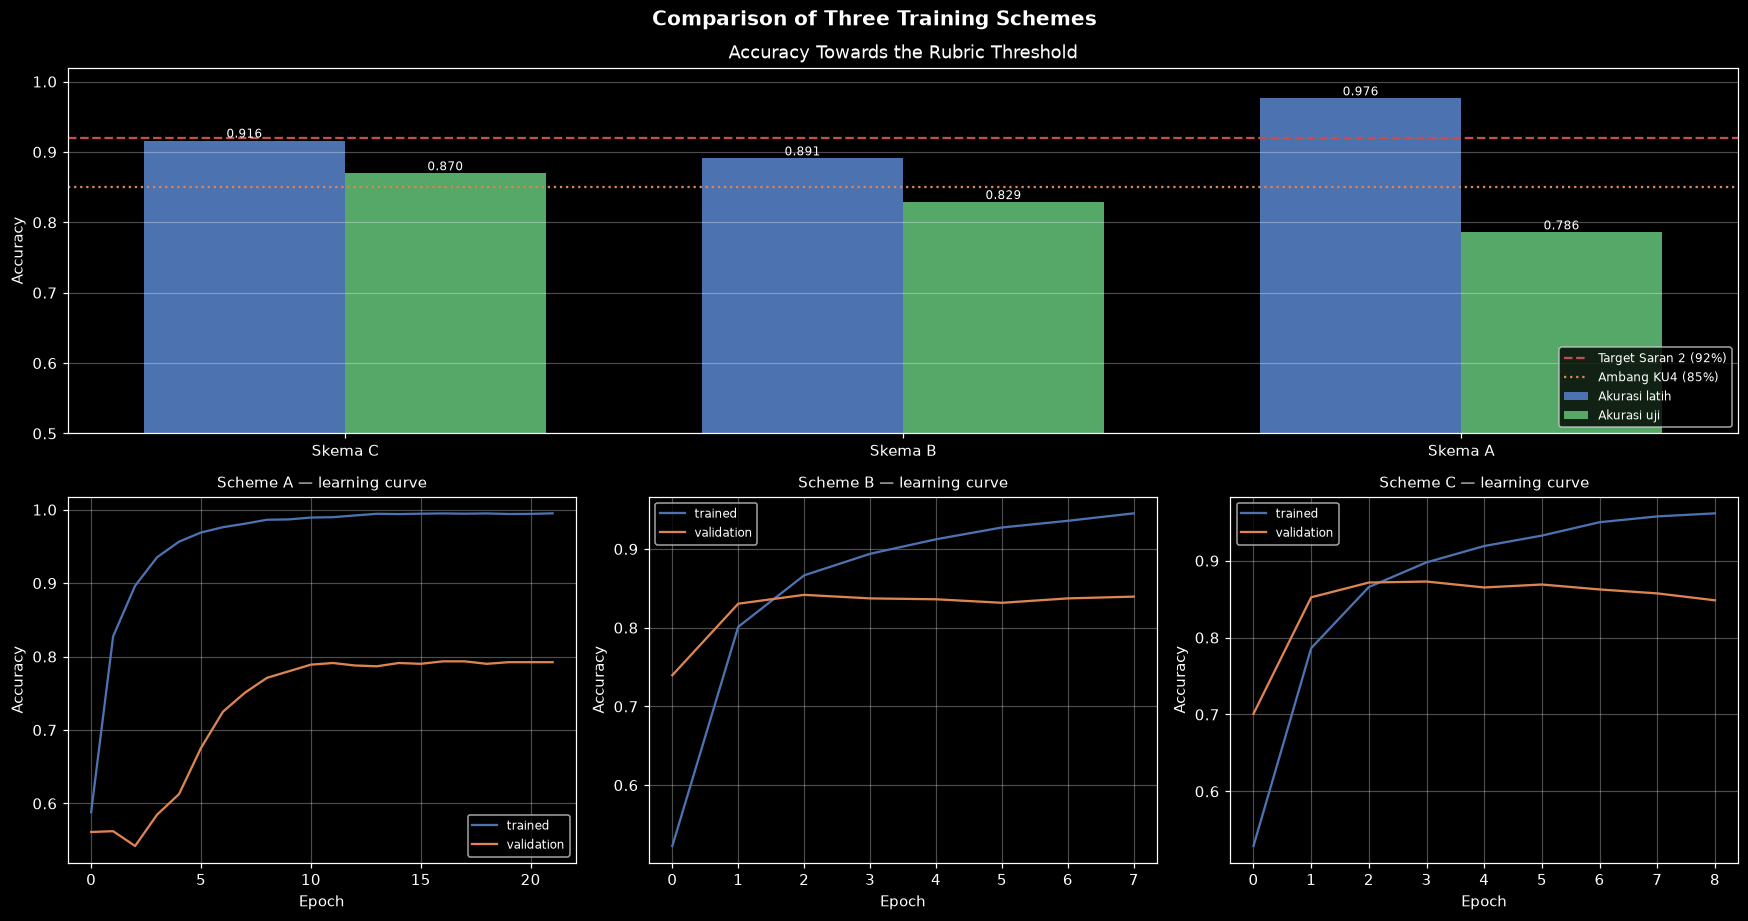

In [90]:
def plot_scheme_comparison(experiments: Dict[str, Dict[str, Any]],
                           table: pd.DataFrame,
                           cfg: TrainingConfig) -> None:
    """Memvisualisasikan perbandingan akurasi dan learning curve."""
    fig = plt.figure(figsize=(16, 8.5))
    fig.suptitle("Comparison of Three Training Schemes", fontsize=13, fontweight="bold")

    # Panel atas: akurasi latih vs uji terhadap threshold rubrik.
    ax_top = plt.subplot2grid((2, 3), (0, 0), colspan=3)
    kode = table["Skema"].tolist()
    posisi = np.arange(len(kode))
    lebar = 0.36

    ax_top.bar(posisi - lebar / 2, table["Akurasi latih"], lebar,
               label="Akurasi latih", color="#4C72B0")
    ax_top.bar(posisi + lebar / 2, table["Akurasi uji"], lebar,
               label="Akurasi uji", color="#55A868")
    ax_top.axhline(cfg.target_accuracy, color="#C44E52", linestyle="--", linewidth=1.5,
                   label=f"Target Saran 2 ({cfg.target_accuracy:.0%})")
    ax_top.axhline(cfg.minimum_accuracy, color="#DD8452", linestyle=":", linewidth=1.5,
                   label=f"Ambang KU4 ({cfg.minimum_accuracy:.0%})")

    for i, (tr, te) in enumerate(zip(table["Akurasi latih"], table["Akurasi uji"])):
        ax_top.text(i - lebar / 2, tr, f"{tr:.3f}", ha="center", va="bottom", fontsize=8)
        ax_top.text(i + lebar / 2, te, f"{te:.3f}", ha="center", va="bottom", fontsize=8)

    ax_top.set_xticks(posisi)
    ax_top.set_xticklabels([f"Skema {k}" for k in kode])
    ax_top.set_ylim(0.5, 1.02)
    ax_top.set_ylabel("Accuracy")
    ax_top.set_title("Accuracy Towards the Rubric Threshold")
    ax_top.legend(fontsize=8, loc="lower right")
    ax_top.grid(axis="y", alpha=0.3)

    # Panel bawah: learning curve.
    for idx, kode_skema in enumerate(["A", "B", "C"]):
        ax = plt.subplot2grid((2, 3), (1, idx))
        riwayat = EXPERIMENTS[kode_skema]["history"]
        ax.plot(riwayat["accuracy"], label="trained", color="#4C72B0")
        ax.plot(riwayat["val_accuracy"], label="validation", color="#DD8452")
        ax.set_title(f"Scheme {kode_skema} — learning curve", fontsize=10)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_scheme_comparison(EXPERIMENTS, comparison, TRAINING)

## 14. Evaluasi Mendalam Model Terbaik

In [92]:
BEST_CODE = comparison.iloc[0]["Skema"]
BEST = EXPERIMENTS[BEST_CODE]

print(f"Model terbaik : Skema {BEST_CODE} — {BEST['spec'].name}")
print(f"Akurasi latih : {BEST['train_accuracy']:.4f}")
print(f"Akurasi uji   : {BEST['test_accuracy']:.4f}")
print(f"Selisih       : {abs(BEST['train_accuracy'] - BEST['test_accuracy']):.4f} "
      f"(selisih kecil menandakan generalisasi yang sehat)")
print()
print("Laporan klasifikasi per kelas (set uji)")
print("-" * 40)
print(classification_report(
    BEST["y_test"], BEST["y_pred"],
    target_names=list(LABEL_ENCODER.classes_),
    digits=4,
    zero_division=0,
))

Model terbaik : Skema C — Sequence Embedding + CNN 1D
Akurasi latih : 0.9162
Akurasi uji   : 0.8697
Selisih       : 0.0464 (selisih kecil menandakan generalisasi yang sehat)

Laporan klasifikasi per kelas (set uji)
----------------------------------------
              precision    recall  f1-score   support

     negatif     0.7880    0.8965    0.8388       705
      netral     0.9326    0.8202    0.8728      1502
     positif     0.8553    0.9187    0.8859      1132

    accuracy                         0.8697      3339
   macro avg     0.8586    0.8785    0.8658      3339
weighted avg     0.8759    0.8697    0.8701      3339



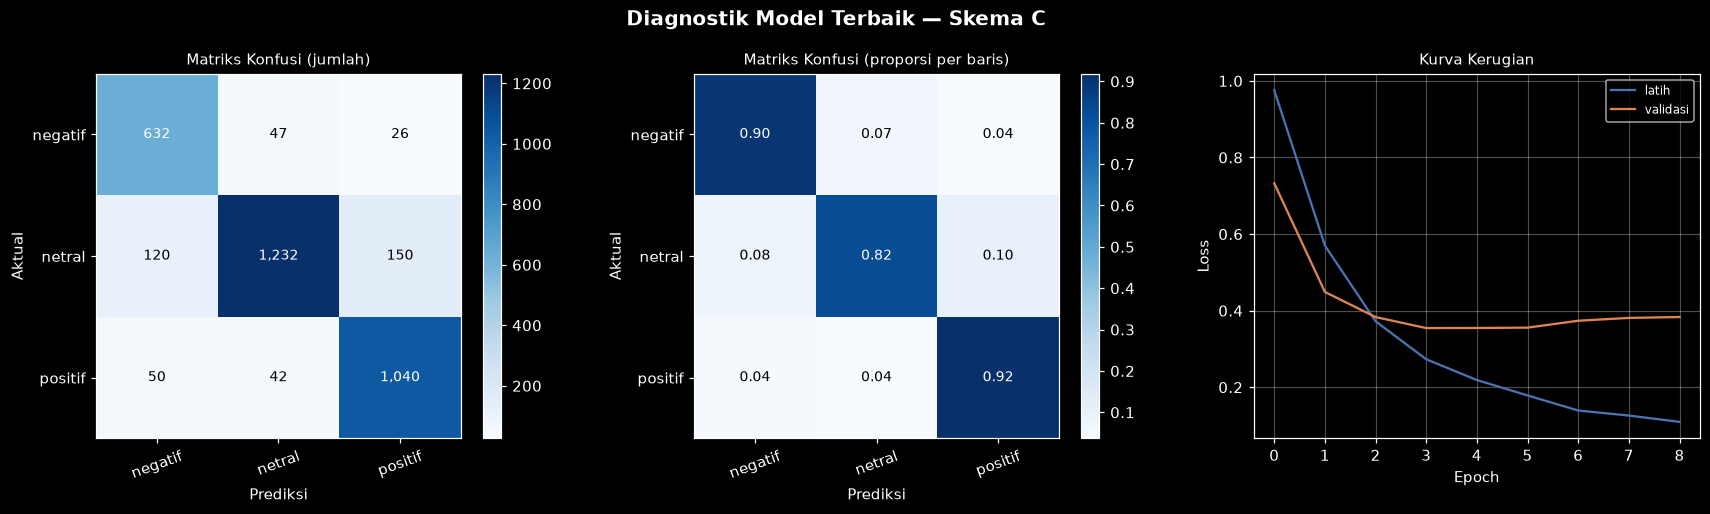

In [94]:
def plot_best_model_diagnostics(hasil: Dict[str, Any], encoder: LabelEncoder) -> None:
    """Menampilkan matriks konfusi (mentah dan ternormalisasi) serta kurva kerugian."""
    matrix = confusion_matrix(hasil["y_test"], hasil["y_pred"])
    normalised = matrix.astype("float") / matrix.sum(axis=1, keepdims=True)
    kelas = list(encoder.classes_)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    fig.suptitle(f"Diagnostik Model Terbaik — Skema {hasil['spec'].code}",
                 fontsize=13, fontweight="bold")

    for ax, data, judul, fmt in (
        (axes[0], matrix, "Matriks Konfusi (jumlah)", "{:,}"),
        (axes[1], normalised, "Matriks Konfusi (proporsi per baris)", "{:.2f}"),
    ):
        im = ax.imshow(data, cmap="Blues")
        ax.set_xticks(range(len(kelas)), kelas, rotation=20)
        ax.set_yticks(range(len(kelas)), kelas)
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
        ax.set_title(judul, fontsize=10)
        ambang = data.max() / 2
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center",
                        color="white" if data[i, j] > ambang else "black", fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.046)

    axes[2].plot(hasil["history"]["loss"], label="latih", color="#4C72B0")
    axes[2].plot(hasil["history"]["val_loss"], label="validasi", color="#DD8452")
    axes[2].set_title("Kurva Kerugian", fontsize=10)
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Loss")
    axes[2].legend(fontsize=8)
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_best_model_diagnostics(BEST, LABEL_ENCODER)

## 15. Pemuatan Ulang Artefak Model

In [95]:
def persist_artifacts(hasil: Dict[str, Any],
                      encoder: LabelEncoder,
                      cfg: TrainingConfig) -> Dict[str, str]:
    """Menyimpan model, vectorizer, dan metadata ke direktori artefak."""
    os.makedirs(cfg.artifact_dir, exist_ok=True)
    spec = hasil["spec"]
    paths: Dict[str, str] = {}

    model_path = os.path.join(cfg.artifact_dir, "model_sentimen.keras")
    hasil["model"].save(model_path)
    paths["model"] = model_path

    if spec.feature_kind == "tfidf":
        vec_path = os.path.join(cfg.artifact_dir, "vectorizer_tfidf.joblib")
        joblib.dump(hasil["vectorizer"], vec_path)
        paths["vectorizer"] = vec_path
    else:
        vocab = hasil["vectorizer"].get_vocabulary()
        vocab_path = os.path.join(cfg.artifact_dir, "kosakata_sequence.json")
        with open(vocab_path, "w", encoding="utf-8") as handle:
            json.dump(vocab, handle, ensure_ascii=False)
        paths["vectorizer"] = vocab_path

    meta = {
        "kode_skema": spec.code,
        "nama_skema": spec.name,
        "jenis_fitur": spec.feature_kind,
        "arsitektur": spec.architecture,
        "panjang_urutan": spec.sequence_length,
        "max_features": spec.max_features,
        "kelas": list(encoder.classes_),
        "akurasi_latih": hasil["train_accuracy"],
        "akurasi_uji": hasil["test_accuracy"],
        "f1_makro": hasil["f1_macro"],
        "ambang_positif": POS_THRESHOLD,
        "ambang_negatif": NEG_THRESHOLD,
        "disimpan_pada": datetime.now().isoformat(timespec="seconds"),
    }
    meta_path = os.path.join(cfg.artifact_dir, "metadata_model.json")
    with open(meta_path, "w", encoding="utf-8") as handle:
        json.dump(meta, handle, ensure_ascii=False, indent=2)
    paths["metadata"] = meta_path

    for jenis, path in paths.items():
        LOGGER.info("Artefak %-11s tersimpan: %s (%.2f MB)",
                    jenis, path, os.path.getsize(path) / (1024 ** 2))
    return paths


ARTIFACT_PATHS = persist_artifacts(BEST, LABEL_ENCODER, TRAINING)
print()
print("Isi direktori artefak:")
for nama in sorted(os.listdir(TRAINING.artifact_dir)):
    print(f"  - {nama}")

23:49:53 | INFO    | Artefak model       tersimpan: artifacts\model_sentimen.keras (8.55 MB)
23:49:53 | INFO    | Artefak vectorizer  tersimpan: artifacts\kosakata_sequence.json (0.06 MB)
23:49:53 | INFO    | Artefak metadata    tersimpan: artifacts\metadata_model.json (0.00 MB)

Isi direktori artefak:
  - kosakata_sequence.json
  - metadata_model.json
  - model_sentimen.keras


## 16. Inferensi — Kategorikal

In [126]:
class SentimentPredictor:

    def __init__(self,
                 model: tf.keras.Model,
                 vectorizer: Any,
                 feature_kind: str,
                 classes: Sequence[str],
                 stem_cache: StemCache) -> None:
        self.model = model
        self.vectorizer = vectorizer
        self.feature_kind = feature_kind
        self.classes = list(classes)
        self._stem_cache = stem_cache

    @classmethod
    def from_artifacts(cls, paths: Dict[str, str], stem_cache: StemCache) -> "SentimentPredictor":
        with open(paths["metadata"], "r", encoding="utf-8") as handle:
            meta = json.load(handle)

        model = tf.keras.models.load_model(paths["model"])

        if meta["jenis_fitur"] == "tfidf":
            vectorizer = joblib.load(paths["vectorizer"])
        else:
            with open(paths["vectorizer"], "r", encoding="utf-8") as handle:
                vocab = json.load(handle)
            # Token khusus ('' untuk padding, '[UNK]') ditambahkan otomatis oleh lapisan.
            vocab_terms = [t for t in vocab if t not in ("", "[UNK]")]
            vectorizer = tf.keras.layers.TextVectorization(
                max_tokens=meta["max_features"],
                standardize=None,
                split="whitespace",
                output_mode="int",
                output_sequence_length=meta["panjang_urutan"],
            )
            vectorizer.set_vocabulary(vocab_terms)

        LOGGER.info("Predictor dimuat dari artefak skema %s (%s).",
                    meta["kode_skema"], meta["arsitektur"].upper())
        return cls(model, vectorizer, meta["jenis_fitur"], meta["kelas"], stem_cache)

    def predict(self, texts: Sequence[str]) -> pd.DataFrame:
        prepared = [self._preprocess(t) for t in texts]
        features = self._vectorize(prepared)
        probabilities = self.model.predict(features, verbose=0)
        indices = np.argmax(probabilities, axis=1)

        result = pd.DataFrame({
            "teks": list(texts),
            "sentimen_prediksi": [self.classes[i] for i in indices],
            "keyakinan": np.round(probabilities.max(axis=1), 4),
        })
        for posisi, nama in enumerate(self.classes):
            result[f"prob_{nama}"] = np.round(probabilities[:, posisi], 4)
        return result

    def predict_one(self, text: str) -> Dict[str, Any]:
        """Memprediksi sentimen satu teks dan mengembalikan ringkasannya."""
        baris = self.predict([text]).iloc[0]
        return {
            "teks": text,
            "sentimen": baris["sentimen_prediksi"],
            "keyakinan": float(baris["keyakinan"]),
        }

    # ----------------------------------------------------------------------------------
    def _preprocess(self, text: str) -> str:
        """Menerapkan pipeline pra-pemrosesan yang identik dengan tahap pelatihan."""
        tokens = normalise_slang(basic_clean(text).split())
        tokens = [t for t in tokens if t not in ACTIVE_STOPWORDS]
        return " ".join(self._stem_cache.stem(t) for t in tokens)

    def _vectorize(self, prepared: Sequence[str]) -> np.ndarray:
        """Mengubah teks menjadi representasi numerik."""
        if self.feature_kind == "tfidf":
            return self.vectorizer.transform(prepared).toarray().astype("float32")
        return self.vectorizer(tf.constant(list(prepared))).numpy()


PREDICTOR = SentimentPredictor.from_artifacts(ARTIFACT_PATHS, STEM_CACHE)
print("Predictor siap digunakan.")
print(f"Kelas keluaran : {PREDICTOR.classes}")

00:00:55 | INFO    | Predictor dimuat dari artefak skema C (CNN).
Predictor siap digunakan.
Kelas keluaran : ['negatif', 'netral', 'positif']


### 16.1 Inferensi untuk Kalimat Uji

In [127]:
KALIMAT_UJI: List[str] = [
    # Diharapkan positif
    "Aplikasi ini sangat membantu saya memahami materi matematika, penjelasannya jelas dan lengkap.",
    "Fiturnya lengkap, gurunya ramah, dan harganya terjangkau untuk pelajar.",
    "Materi tersusun rapi dan mudah dipahami, sangat direkomendasikan untuk belajar mandiri.",
    # Diharapkan negatif
    "Aplikasinya sering error dan lemot sekali, sudah bayar langganan tapi materi tidak bisa dibuka.",
    "Sangat mengecewakan, iklannya terlalu banyak dan sering keluar sendiri saat sedang belajar.",
    "Materi sedikit tapi harganya mahal sekali, saya menyesal berlangganan aplikasi ini.",
    # Diharapkan netral atau ambivalen
    "Aplikasi lumayan, ada beberapa fitur yang perlu diperbaiki tetapi masih bisa digunakan.",
    "Saya baru memakai aplikasi ini selama tiga hari untuk mengerjakan tugas sekolah.",
    # Uji negasi:
    "Aplikasi ini tidak membantu sama sekali dan penjelasannya tidak jelas.",
]

hasil_inferensi = PREDICTOR.predict(KALIMAT_UJI)

print("HASIL INFERENSI — OUTPUT KELAS KATEGORIKAL")
print("=" * 42)
for _, baris in hasil_inferensi.iterrows():
    print(f"\nTeks      : {baris['teks']}")
    print(f"Sentimen  : {baris['sentimen_prediksi'].upper()}   "
          f"(keyakinan {baris['keyakinan']:.2%})")
    print(f"Probabilitas -> negatif {baris['prob_negatif']:.4f} | "
          f"netral {baris['prob_netral']:.4f} | positif {baris['prob_positif']:.4f}")
print("\n" + "=" * 100)

HASIL INFERENSI — OUTPUT KELAS KATEGORIKAL

Teks      : Aplikasi ini sangat membantu saya memahami materi matematika, penjelasannya jelas dan lengkap.
Sentimen  : POSITIF   (keyakinan 99.42%)
Probabilitas -> negatif 0.0005 | netral 0.0052 | positif 0.9942

Teks      : Fiturnya lengkap, gurunya ramah, dan harganya terjangkau untuk pelajar.
Sentimen  : POSITIF   (keyakinan 63.52%)
Probabilitas -> negatif 0.1369 | netral 0.2279 | positif 0.6352

Teks      : Materi tersusun rapi dan mudah dipahami, sangat direkomendasikan untuk belajar mandiri.
Sentimen  : POSITIF   (keyakinan 99.15%)
Probabilitas -> negatif 0.0002 | netral 0.0083 | positif 0.9915

Teks      : Aplikasinya sering error dan lemot sekali, sudah bayar langganan tapi materi tidak bisa dibuka.
Sentimen  : NEGATIF   (keyakinan 99.65%)
Probabilitas -> negatif 0.9965 | netral 0.0033 | positif 0.0002

Teks      : Sangat mengecewakan, iklannya terlalu banyak dan sering keluar sendiri saat sedang belajar.
Sentimen  : NEGATIF   (keyaki

In [130]:
# Tampilan tabular dari hasil inferensi.
hasil_inferensi[["teks", "sentimen_prediksi", "keyakinan",
                 "prob_negatif", "prob_netral", "prob_positif"]]

,teks,sentimen_prediksi,keyakinan,prob_negatif,prob_netral,prob_positif
0,"Aplikasi ini sangat membantu saya memahami materi matematika, penjelasannya ...",positif,0.9942,0.0005,0.0052,0.9942
1,"Fiturnya lengkap, gurunya ramah, dan harganya terjangkau untuk pelajar.",positif,0.6352,0.1369,0.2279,0.6352
2,"Materi tersusun rapi dan mudah dipahami, sangat direkomendasikan untuk belaj...",positif,0.9915,0.0002,0.0083,0.9915
3,"Aplikasinya sering error dan lemot sekali, sudah bayar langganan tapi materi...",negatif,0.9965,0.9965,0.0033,0.0002
4,"Sangat mengecewakan, iklannya terlalu banyak dan sering keluar sendiri saat ...",negatif,0.9983,0.9983,0.0016,0.0001
5,"Materi sedikit tapi harganya mahal sekali, saya menyesal berlangganan aplika...",negatif,0.9652,0.9652,0.0307,0.0040
6,"Aplikasi lumayan, ada beberapa fitur yang perlu diperbaiki tetapi masih bisa...",positif,0.9407,0.0046,0.0546,0.9407
7,Saya baru memakai aplikasi ini selama tiga hari untuk mengerjakan tugas seko...,netral,0.9024,0.0185,0.9024,0.0792
8,Aplikasi ini tidak membantu sama sekali dan penjelasannya tidak jelas.,negatif,0.8022,0.8022,0.0668,0.1310


### 16.2 Inferensi untuk Sampel Nyata dengan Pembanding Label

In [131]:
sampel_nyata = df_prep.sample(n=10, random_state=SEED).reset_index(drop=True)
prediksi_nyata = PREDICTOR.predict(sampel_nyata["ulasan"].tolist())

perbandingan = pd.DataFrame({
    "ulasan": sampel_nyata["ulasan"].str.slice(0, 70) + "...",
    "rating": sampel_nyata["rating"],
    "label_aktual": sampel_nyata["sentimen"],
    "prediksi": prediksi_nyata["sentimen_prediksi"],
    "keyakinan": prediksi_nyata["keyakinan"],
})
perbandingan["cocok"] = np.where(
    perbandingan["label_aktual"] == perbandingan["prediksi"], "ya", "tidak")

akurasi_sampel = float((perbandingan["cocok"] == "ya").mean())
print(f"Kecocokan pada sampel ini : {akurasi_sampel:.0%} ({int(akurasi_sampel * 10)} dari 10)")
print()
perbandingan

Kecocokan pada sampel ini : 80% (8 dari 10)



,ulasan,rating,label_aktual,prediksi,keyakinan,cocok
0,"Tolong ditambahkan fitur ketika menghapus komentar, pengajar juga tida...",4,netral,negatif,0.9362,tidak
1,apknya sering keluar sendiri padahal jaringan saya bagus dan penyimpan...,2,positif,positif,0.8138,ya
2,"Lumayan,,tapi kadang error...",3,netral,netral,0.5182,ya
3,Angela yu course is the best for web development...,5,netral,netral,0.9902,ya
4,bagus tapi aku aj yang dodol pas pertama kali 🙊...,5,positif,positif,0.8553,ya
5,pernah ketipu 2 JT an di aplikasi ini pas SMA...,1,netral,netral,0.9524,ya
6,Kok bayar sih?? Katanya gratis?...,3,positif,positif,0.9024,ya
7,"I really love this app , it's so cool. But could you add more features...",5,netral,netral,0.9912,ya
8,Bagusi tapi lemot😂😂😂...,4,negatif,positif,0.4816,tidak
9,sangat cocok untuk saya...,4,positif,positif,0.9844,ya


In [132]:
# Fungsi praktis untuk memprediksi satu teks tunggal.
def prediksi_cepat(teks: str) -> None:
    """Menampilkan hasil prediksi satu teks dalam format ringkas."""
    hasil = PREDICTOR.predict_one(teks)
    print(f'Teks     : "{hasil["teks"]}"')
    print(f'Sentimen : {hasil["sentimen"].upper()} (keyakinan {hasil["keyakinan"]:.2%})')


prediksi_cepat("Penjelasan materinya sangat bagus dan mudah dimengerti, saya jadi semangat belajar.")
print()
prediksi_cepat("Aplikasi berat, sering macet, dan tidak sebanding dengan biaya langganannya.")
print()
prediksi_cepat("Saya menggunakan aplikasi ini untuk mengerjakan tugas sekolah setiap hari.")

Teks     : "Penjelasan materinya sangat bagus dan mudah dimengerti, saya jadi semangat belajar."
Sentimen : POSITIF (keyakinan 99.40%)

Teks     : "Aplikasi berat, sering macet, dan tidak sebanding dengan biaya langganannya."
Sentimen : NEGATIF (keyakinan 98.28%)

Teks     : "Saya menggunakan aplikasi ini untuk mengerjakan tugas sekolah setiap hari."
Sentimen : POSITIF (keyakinan 73.76%)


## 17. Validasi Compliance

In [138]:
def build_compliance_matrix(frame: pd.DataFrame,
                            table: pd.DataFrame,
                            experiments: Dict[str, Dict[str, Any]],
                            hasil_infer: pd.DataFrame,
                            cfg: TrainingConfig) -> pd.DataFrame:

    n = len(frame)
    n_kelas = frame["sentimen"].nunique()
    semua_min = bool((table["Akurasi uji"] >= cfg.minimum_accuracy).all())
    ada_target = bool(((table["Akurasi latih"] > cfg.target_accuracy) &
                       (table["Akurasi uji"] > cfg.target_accuracy)).any())
    akurasi_terbaik = float(table["Akurasi uji"].max())
    arsitektur = sorted({h["spec"].architecture.upper() for h in experiments.values()})

    item = [
        ("Kriteria Utama 1", "Data hasil scraping mandiri, >= 3.000 sampel",
         ">= 3.000", f"{n:,} sampel", n >= 3_000),
        ("Kriteria Utama 2", "Ekstraksi fitur dan pelabelan data",
         "Ada", "Leksikon terbobot + TF-IDF/Sequence", True),
        ("Kriteria Utama 3", "Algoritma pelatihan machine learning",
         "Ada", ", ".join(arsitektur), True),
        ("Kriteria Utama 4", "Akurasi testing set >= 85%",
         ">= 85%", f"{akurasi_terbaik:.2%} (terbaik)", akurasi_terbaik >= cfg.minimum_accuracy),
        ("Saran 1", "Menggunakan algoritma deep learning",
         "Ya", f"3 arsitektur neural: {', '.join(arsitektur)}", True),
        ("Saran 2", "Akurasi training dan testing > 92%",
         "> 92%", f"{'terpenuhi' if ada_target else 'belum'} pada minimal satu skema", ada_target),
        ("Saran 2 (lanjutan)", "Skema lain tetap >= 85%",
         ">= 85%", f"{'seluruh skema memenuhi' if semua_min else 'ada yang di bawah'}", semua_min),
        ("Saran 3", "Dataset memiliki minimal tiga kelas",
         ">= 3", f"{n_kelas} kelas: {', '.join(CLASS_ORDER)}", n_kelas >= 3),
        ("Saran 4", "Jumlah data minimal 10.000 sampel",
         ">= 10.000", f"{n:,} sampel", n >= cfg.minimum_samples),
        ("Saran 5", "Tiga skema pelatihan, minimal 2 kombinasi berbeda",
         "3 skema", f"{len(table)} skema, 3 dimensi divariasikan", len(table) >= 3),
        ("Saran 6", "Inferensi menghasilkan kelas kategorikal",
         "Ada", f"{len(hasil_infer)} kalimat uji + 10 sampel nyata", len(hasil_infer) > 0),
    ]

    return pd.DataFrame([
        {"Item": b, "Terms": k, "Target": t, "Actual": a,
         "Status": "LULUS" if ok else "PERIKSA ULANG"}
        for b, k, t, a, ok in item
    ])


compliance = build_compliance_matrix(df_prep, comparison, EXPERIMENTS,
                                     hasil_inferensi, TRAINING)

n_lulus = int((compliance["Status"] == "LULUS").sum())
print(f"Item rubrik terpenuhi : {n_lulus} dari {len(compliance)}")
if n_lulus < len(compliance):
    print("\nItem yang perlu ditinjau:")
    for _, r in compliance[compliance["Status"] != "LULUS"].iterrows():
        print(f"  - {r['Item']}: {r['Actual']}")
print()
compliance

Item rubrik terpenuhi : 9 dari 11

Item yang perlu ditinjau:
  - Saran 2: belum pada minimal satu skema
  - Saran 2 (lanjutan): ada yang di bawah



,Item,Terms,Target,Actual,Status
0,Kriteria Utama 1,"Data hasil scraping mandiri, >= 3.000 sampel",>= 3.000,"11,128 sampel",LULUS
1,Kriteria Utama 2,Ekstraksi fitur dan pelabelan data,Ada,Leksikon terbobot + TF-IDF/Sequence,LULUS
2,Kriteria Utama 3,Algoritma pelatihan machine learning,Ada,"BILSTM, CNN, DENSE",LULUS
3,Kriteria Utama 4,Akurasi testing set >= 85%,>= 85%,86.97% (terbaik),LULUS
4,Saran 1,Menggunakan algoritma deep learning,Ya,"3 arsitektur neural: BILSTM, CNN, DENSE",LULUS
5,Saran 2,Akurasi training dan testing > 92%,> 92%,belum pada minimal satu skema,PERIKSA ULANG
6,Saran 2 (lanjutan),Skema lain tetap >= 85%,>= 85%,ada yang di bawah,PERIKSA ULANG
7,Saran 3,Dataset memiliki minimal tiga kelas,>= 3,"3 kelas: negatif, netral, positif",LULUS
8,Saran 4,Jumlah data minimal 10.000 sampel,>= 10.000,"11,128 sampel",LULUS
9,Saran 5,"Tiga skema pelatihan, minimal 2 kombinasi berbeda",3 skema,"3 skema, 3 dimensi divariasikan",LULUS
